In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import os

class QLearningAgent:
    def __init__(self, n_states, n_actions, alpha=0.1, gamma=0.99, epsilon=1.0, epsilon_decay=0.995, min_epsilon=0.01):
        self.n_states = n_states
        self.n_actions = n_actions
        self.alpha = alpha       # Learning rate
        self.gamma = gamma       # Discount factor
        self.epsilon = epsilon   # Exploration rate
        self.epsilon_decay = epsilon_decay
        self.min_epsilon = min_epsilon
        
        self.q_table = np.zeros((n_states, n_actions))

    def choose_action(self, state):
        if np.random.rand() < self.epsilon:
            return np.random.choice(self.n_actions) # Explore
        else:
            return np.argmax(self.q_table[state])   # Exploit

    def update(self, state, action, reward, next_state, terminated):
        best_next_action = np.argmax(self.q_table[next_state])
        td_target = reward + (self.gamma * self.q_table[next_state][best_next_action] * (not terminated))
        td_error = td_target - self.q_table[state][action]
        self.q_table[state][action] += self.alpha * td_error

    def decay_epsilon(self):
        self.epsilon = max(self.min_epsilon, self.epsilon * self.epsilon_decay)

In [2]:
# Initialize Taxi-v4 Environment
env = gym.make("Taxi-v4")
n_states = env.observation_space.n
n_actions = env.action_space.n

# Instantiate Agent
agent = QLearningAgent(n_states=n_states, n_actions=n_actions)

n_episodes = 3000
max_steps = 100
rewards_history = []

print("Training Q-Learning Agent on Taxi-v4...")
for episode in range(n_episodes):
    state, _ = env.reset()
    total_reward = 0
    
    for step in range(max_steps):
        action = agent.choose_action(state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        
        agent.update(state, action, reward, next_state, terminated)
        state = next_state
        total_reward += reward
        
        if terminated or truncated:
            break
            
    agent.decay_epsilon()
    rewards_history.append(total_reward)
    
    if (episode + 1) % 500 == 0:
        print(f"Episode {episode + 1}/{n_episodes} - Avg Reward (last 100): {np.mean(rewards_history[-100:]):.2f}")

env.close()

Training Q-Learning Agent on Taxi-v4...
Episode 500/3000 - Avg Reward (last 100): -101.15
Episode 1000/3000 - Avg Reward (last 100): -27.59
Episode 1500/3000 - Avg Reward (last 100): 0.27
Episode 2000/3000 - Avg Reward (last 100): 6.17
Episode 2500/3000 - Avg Reward (last 100): 7.31
Episode 3000/3000 - Avg Reward (last 100): 7.42


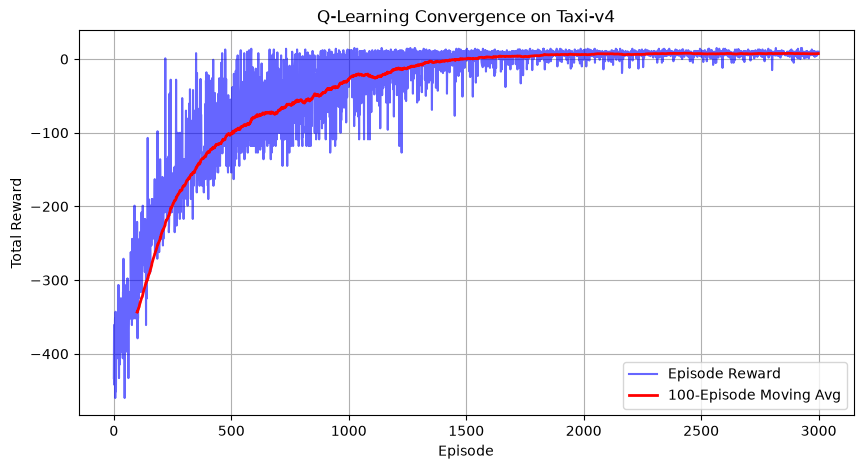

In [3]:
plt.figure(figsize=(10, 5))
plt.plot(rewards_history, label="Episode Reward", color="blue", alpha=0.6)
# Rolling average curve
rolling_avg = np.convolve(rewards_history, np.ones(100)/100, mode='valid')
plt.plot(np.arange(99, len(rewards_history)), rolling_avg, label="100-Episode Moving Avg", color="red", linewidth=2)

plt.title("Q-Learning Convergence on Taxi-v4")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
from gymnasium.wrappers import RecordVideo

env_video = gym.make("Taxi-v4", render_mode="rgb_array")
env_video = RecordVideo(env_video, video_folder="recorded_video", name_prefix="notebook-agent", episode_trigger=lambda e: True)

for _ in range(2):
    state, _ = env_video.reset()
    terminated = False
    truncated = False
    while not terminated and not truncated:
        action = np.argmax(agent.q_table[state])
        state, reward, terminated, truncated, _ = env_video.step(action)

env_video.close()
print("Evaluation video recorded successfully!")

c:\Users\Dell 8th\Desktop\rl-assignment\venv\Lib\site-packages\gymnasium\wrappers\rendering.py:298: UserWarning: WARN: Overwriting existing videos at c:\Users\Dell 8th\Desktop\rl-assignment\recorded_video folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Evaluation video recorded successfully!
